In [1]:
import numpy as np
from astropy.cosmology import Planck18 as cosmo
from astropy.cosmology import z_at_value

In [2]:
z = 0.1
L = 75/cosmo.h
r0 = cosmo.comoving_distance(z)
r0

<Quantity 432.56569774 Mpc>

In [3]:
z_at_value(func=cosmo.comoving_distance, fval=r0)

<Quantity 0.1 redshift>

In [4]:
def get_xtiling_dc_z_center(n, z0=0.1, L=75/cosmo.h):
    r0 = cosmo.comoving_distance(z0)
    
    get_theta = lambda n: np.arctan2((n-1)*L, r0.value)
    r = r0/np.cos(get_theta(n))
    z = z_at_value(func=cosmo.comoving_distance, fval=r)
    return r , z

def get_xtiling_dc_z_edge(n, z0=0.1, L=75/cosmo.h):
    r0 = cosmo.comoving_distance(z0)
    get_theta = lambda n: np.arctan2(L/2 + (n-1)*L, r0.value)
    r = r0/np.cos(get_theta(n))
    z = z_at_value(func=cosmo.comoving_distance, fval=r)
    return r , z 

In [5]:
n = np.arange(1, 4)
get_xtiling_dc_z_edge(n), get_xtiling_dc_z_center(n)

((<Quantity [436.10196349, 463.42166559, 513.72081455] Mpc>,
  <Quantity [0.10083837, 0.10732748, 0.11933188] redshift>),
 (<Quantity [432.56569774, 446.54276576, 486.06842937] Mpc>,
  <Quantity [0.1       , 0.10331577, 0.11272314] redshift>))

In [6]:
from matplotlib.patches import Rectangle, Arc
from matplotlib import pyplot as plt

In [92]:
def add_square(ax, x, y, L, color='black', **kwargs):
    ax.add_patch(Rectangle((x-L/2, y-L/2), L, L, color=color, fill=False, **kwargs))

def add_arc(ax, x, y, r, color='black', theta1=0, theta2=40, linestyle='--', linewidth=1, **kwargs):
    ax.add_patch(Arc((x, y), 2*r, 2*r, theta1=theta1, theta2=theta2, color=color, linestyle=linestyle, linewidth=linewidth, **kwargs))

def fill_between_arcs_simple(ax, x, y, r1, r2, theta1=0, theta2=360, color='skyblue', alpha=0.5, **kwargs):
    """
    使用fill_between填充两个同心圆弧之间的区域（更简单的方法）
    """
    # 确保r1 < r2
    if r1 > r2:
        r1, r2 = r2, r1
    
    # 将角度转换为弧度
    theta1_rad = np.deg2rad(theta1)
    theta2_rad = np.deg2rad(theta2)
    
    # 生成角度数组
    angles = np.linspace(theta1_rad, theta2_rad, 100)
    
    # 计算内外圆弧上的点
    x_inner = x + r1 * np.cos(angles)
    y_inner = y + r1 * np.sin(angles)
    x_outer = x + r2 * np.cos(angles)
    y_outer = y + r2 * np.sin(angles)
    
    # 使用fill_between填充区域
    ax.fill(np.concatenate([x_outer, x_inner[::-1]]), 
            np.concatenate([y_outer, y_inner[::-1]]), 
            color=color, alpha=alpha, **kwargs)
    
def plot_tiling(ax, n=3, z0=0.1, L=75/cosmo.h, theta1=0, theta2=50, colors=['c', 'g', 'r', 'b', 'm', 'y', 'k']):
    """
    绘制平铺结构和相关的圆弧
    
    参数:
    ax: matplotlib坐标轴对象
    n: 平铺层数
    z0: 参考红移
    L: 平铺尺寸
    theta1, theta2: 圆弧角度范围
    colors: 颜色列表
    """
    r0 = cosmo.comoving_distance(z0)
    r0_val = r0.value / 100
    L_val = L / 100
    
    # 绘制原点
    ax.plot(0, 0, 'ok')
    
    # 绘制平铺结构
    for i in range(1, n + 1):
        r, z = get_xtiling_dc_z_center(i, z0, L)
        r_val = r.value / 100
        
        # 绘制中心圆弧
        add_arc(ax, 0, 0, r_val, color=colors[i], linestyle='--', theta1=theta1, theta2=theta2)
        
        # 绘制中心点和正方形
        center = [r0_val, L_val * (i - 1)]
        ax.plot(center[0], center[1], 'o', color=colors[i], 
                label=f'Tiling {i}, z={z.value:.3f}, dc={r.value:.1f} Mpc')
        add_square(ax, center[0], center[1], L_val, color='k', linestyle='--', zorder=-1)
        
        # 绘制相邻正方形
        add_square(ax, center[0] - L_val, center[1], L_val, color='gray', linestyle='--', zorder=-1)
        add_square(ax, center[0] + L_val, center[1], L_val, color='gray', linestyle='--', zorder=-1)
    
    # 绘制参考圆弧
    radii = [
        r0_val - 3*L_val/2, 
        r0_val + 3*L_val/2
    ]
    styles = ['--', '--']
    arc_colors = ['k', 'k']
    
    for radius, linestyle, color in zip(radii, styles, arc_colors):
        add_arc(ax, 0, 0, radius, color=color, linestyle=linestyle, 
                theta1=theta1, theta2=theta2, linewidth=1.5)
    
    # 绘制边界线
    max_radius = r0_val + 3*L_val/2
    angles = [theta1, theta2]
    
    for angle in angles:
        x_end = max_radius * np.cos(np.radians(angle))
        y_end = max_radius * np.sin(np.radians(angle))
        ax.plot([0, x_end], [0, y_end], 'k-', linewidth=1.5)
        
    # 绘制阴影
    fill_between_arcs_simple(ax, 0, 0, r0_val - L_val/2, r0_val + L_val/2, theta1=theta1, theta2=theta2, color='skyblue')
    # 绘制阴影
    fill_between_arcs_simple(ax, 0, 0, r0_val + L_val/2, r0_val + 2*L_val/2, theta1=theta1, theta2=theta2, color='pink')

In [93]:
np.degrees(np.arctan2(7*L/2, cosmo.comoving_distance(0.1).value - L/2))

np.float64(45.81078768519474)

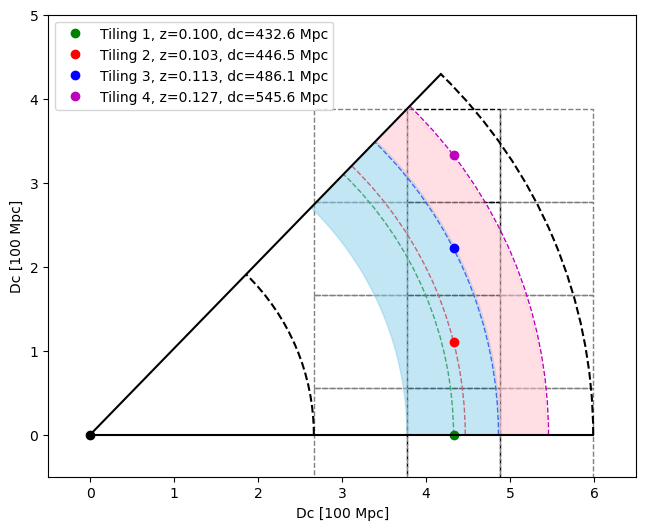

In [94]:
fig, ax = plt.subplots(figsize=(8, 6))
ax.set_aspect('equal')
plot_tiling(ax, 4, theta2=45.8)
ax.legend()
ax.set_xlim(-0.5, 6.5)
ax.set_ylim(-0.5, 5)
ax.set_xlabel('Dc [100 Mpc]')
ax.set_ylabel('Dc [100 Mpc]')

fig.savefig('img_tng_tiling_coverage.png')

In [40]:
r0 = cosmo.comoving_distance(z)
r_min = r0 - L/2 * r0.unit
r_max = r0 + L * r0.unit
z_min = z_at_value(cosmo.comoving_distance, r_min)
z_max = z_at_value(cosmo.comoving_distance, r_max)
print(f'{z_min}, {z_max}')

fmin = 1420.40575177 /(1 + z_min)
fmax = 1420.40575177 /(1 + z_max)
print(f'{fmin}, {fmax}')

0.08690675833292023 redshift, 0.12645374620586913 redshift
1306.8331214984762, 1260.9534626292668


In [54]:
np.arange(1260, 1307, 0.03)

array([1260.  , 1260.03, 1260.06, ..., 1306.92, 1306.95, 1306.98],
      shape=(1567,))

In [58]:
np.linspace(1260, 1306.98, 1567)

array([1260.  , 1260.03, 1260.06, ..., 1306.92, 1306.95, 1306.98],
      shape=(1567,))